# 05 · Detectors on simulated slices: calibration and a fault-magnitude sweep

**Goal.** Run the first real detectors on simulator data, compare them fairly, and see how detection delay depends on fault size.

- **Detectors** (`src/slicead/detectors/`), all shape-agnostic: each monitors every KPI stream in both directions, and the alarm is the maximum over streams.
  - Shewhart threshold, on raw z-scores and on whitened residuals.
  - EWMA ($\lambda = 0.2$) on whitened residuals.
  - Two-sided per-stream CUSUM ($k = 0.5$, tuned to a 1-sd shift), on raw z-scores and on whitened residuals.
- **Training.** Each detector's stream model (mean, sd, AR(1) coefficient) is fitted on separate fault-free runs, as a deployed system would do.
- **Calibration.** Every detector gets the same ARL to false alarm, **1,000 windows (100 s)**, measured on long fault-free runs (`src/slicead/eval/`).
- **Sweep.** All seven faults of notebook 04 at strengths $s \in \{0.03, 0.1, 0.25, 0.5, 1\}$. Strength scales the log of the fault factor, so a URLLC surge of factor 5 at $s = 1$ becomes $5^{0.1} \approx 1.17$ at $s = 0.1$. The fault starts at 10 s, and delays are counted up to 30 s after it.

**Monitored streams:** throughput, latency, jitter and loss of each slice, except URLLC loss. That stream is almost always zero, so a single lost packet is a 50-sd event; it needs a count model, not a Gaussian detector. As a result the URLLC loss burst is expected to go undetected here.

**Run it** from the project root (about 6 minutes):

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/05_detectors.ipynb
```

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import CUSUM, EWMA, Shewhart, StreamModel, stream_array
from slicead.eval import (arl_with_restarts, calibrate_per_stream, calibrate_threshold, first_alarms,
                          summarize_delays)

SEED = 20261022
OUT = Path("../results/05_detectors")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)
(REPORT / "figures").mkdir(parents=True, exist_ok=True)
(REPORT / "tables").mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"05_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"05_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"05_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # categorical slots 1-5, fixed order
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
SLICES = ["eMBB", "URLLC", "mMTC"]
KPIS = ["throughput_mbps", "latency_ms", "jitter_ms", "loss_pct"]
STREAMS = [(s, k) for s in SLICES for k in KPIS if not (s == "URLLC" and k == "loss_pct")]
SHORT = {"throughput_mbps": "thr", "latency_ms": "lat", "jitter_ms": "jit", "loss_pct": "loss"}
STREAM_LABELS = [f"{s} {SHORT[k]}" for s, k in STREAMS]
TARGET_ARL = 1000                     # windows = 100 s
CHANGE_S, HORIZON_W = 10.0, 300       # fault at 10 s; delays counted up to 30 s after it
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]
print(len(STREAMS), "streams:", ", ".join(STREAM_LABELS))

11 streams: eMBB thr, eMBB lat, eMBB jit, eMBB loss, URLLC thr, URLLC lat, URLLC jit, mMTC thr, mMTC lat, mMTC jit, mMTC loss


## 1. Training and calibration data

Two separate sets of fault-free runs:

- **training:** 8 runs of 5 minutes, used to fit each stream's mean, sd and AR(1) coefficient;
- **calibration:** 32 runs of 5 minutes (96,000 windows in all, about 96 false alarms at the target ARL), used to set the thresholds.

In [2]:
t0 = time.time()
train = simulate(cfg, n_windows=3000, n_runs=8, seed=SEED)
calib = simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1)
model = StreamModel().fit(stream_array(train, STREAMS))
Xcal = stream_array(calib, STREAMS)
INPUTS = {"raw": model.standardize, "whitened": model.whiten}
Zcal = {name: f(Xcal) for name, f in INPUTS.items()}
print(f"simulated in {time.time() - t0:.0f} s")
pd.DataFrame({"mean": model.mu, "sd": model.sd, "AR(1) phi": model.phi}, index=STREAM_LABELS).round(3)

simulated in 63 s


,mean,sd,AR(1) phi
eMBB thr,44.825,33.559,0.614
eMBB lat,8.398,15.521,0.777
eMBB jit,1.876,3.112,0.275
eMBB loss,0.769,3.413,0.649
URLLC thr,2.001,0.126,0.010
URLLC lat,0.042,0.007,0.618
URLLC jit,0.021,0.004,0.331
mMTC thr,7.992,0.178,-0.001
mMTC lat,0.185,0.027,0.724
mMTC jit,0.059,0.011,0.593


## 2. Calibration: the heaviest tail sets the threshold

Two ways to set a threshold for "the maximum over 11 streams":

- **common:** one threshold for every stream's statistic;
- **equalised:** each stream first gets its own threshold, giving it ARL = 11 × 1000 on its own. One final factor then brings the combination to ARL 1000 (`calibrate_per_stream`). Every stream gets an equal share of the false-alarm budget.

We also compare against **i.i.d. theory**. For 11 independent standard-normal streams, Shewhart needs $|z| \ge 3.9$ and the two-sided CUSUM about 5.9 (Siegmund) for ARL 1000. The question is how far the real KPI streams are from that.

In [3]:
from scipy.optimize import brentq
from scipy.stats import norm

S = len(STREAMS)
def siegmund_one_sided(h, k=0.5):
    D, b = -k, h + 1.166
    return (np.exp(-2 * D * b) + 2 * D * b - 1) / (2 * D**2)
h_iid = {"Shewhart": norm.isf((1 - (1 - 1 / TARGET_ARL) ** (1 / S)) / 2),
         "CUSUM": brentq(lambda h: siegmund_one_sided(h) / 2 / S - TARGET_ARL, 0.5, 50)}

DETECTORS = {   # name -> (factory, input)
    "Shewhart, raw": (Shewhart, "raw"),
    "Shewhart, whitened": (Shewhart, "whitened"),
    "EWMA, whitened": (lambda: EWMA(0.2), "whitened"),
    "CUSUM, raw": (lambda: CUSUM(0.5), "raw"),
    "CUSUM, whitened": (lambda: CUSUM(0.5), "whitened"),
}

rows, calibrated = [], {}
for name, (make, inp) in DETECTORS.items():
    common = make()
    h_common, _ = calibrate_threshold(common, Zcal[inp], TARGET_ARL)
    eq = make()
    c_eq, arl_eq = calibrate_per_stream(eq, Zcal[inp], TARGET_ARL)
    calibrated[name] = dict(common=(common, h_common), equalised=(eq, c_eq), input=inp)
    family = name.split(",")[0]
    iid = h_iid.get(family)
    arl_iid = arl_with_restarts(make(), Zcal[inp], iid) if iid else np.nan
    rows.append(dict(detector=name, h_iid=iid, arl_if_iid_threshold=arl_iid, h_common=h_common,
                     equalised_factor=c_eq, stream_h_min=eq.scale.min(), stream_h_max=eq.scale.max(),
                     heaviest_stream=STREAM_LABELS[int(np.argmax(eq.scale))]))
calib_table = pd.DataFrame(rows)
calib_table.to_csv(OUT / "calibration.csv", index=False)
calib_table.round(2)

,detector,h_iid,arl_if_iid_threshold,h_common,equalised_factor,stream_h_min,stream_h_max,heaviest_stream
0,"Shewhart, raw",3.91,27.21,8.97,0.99,1.90,10.99,eMBB loss
1,"Shewhart, whitened",3.91,24.69,9.55,1.00,2.84,12.39,eMBB loss
2,"EWMA, whitened",NaN,NaN,7.96,0.99,2.29,10.35,eMBB loss
3,"CUSUM, raw",8.14,26.50,35.66,0.95,8.23,63.83,eMBB loss
4,"CUSUM, whitened",8.14,101.37,17.84,0.95,5.02,31.82,eMBB loss


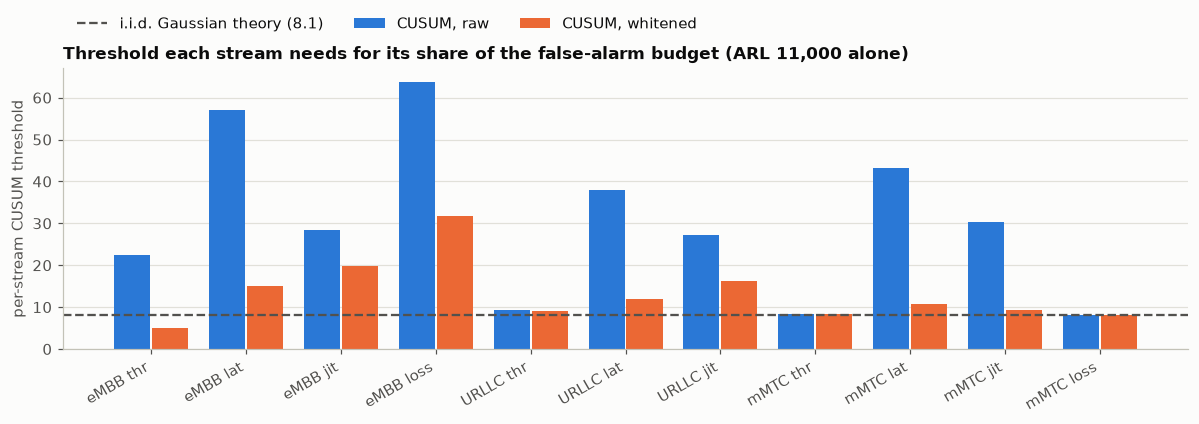

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(S)
w = 0.38
for i, (name, col) in enumerate([("CUSUM, raw", PALETTE[0]), ("CUSUM, whitened", PALETTE[1])]):
    ax.bar(x + (i - 0.5) * (w + 0.02), calibrated[name]["equalised"][0].scale, width=w, color=col, label=name)
h_one = brentq(lambda h: siegmund_one_sided(h) / 2 - S * TARGET_ARL, 0.5, 50)
ax.axhline(h_one, color=INK2, ls="--", lw=1.5, label=f"i.i.d. Gaussian theory ({h_one:.1f})")
ax.set_xticks(x, STREAM_LABELS, rotation=30, ha="right")
ax.grid(axis="x", visible=False)
ax.set_ylabel("per-stream CUSUM threshold")
ax.set_title("Threshold each stream needs for its share of the false-alarm budget (ARL 11,000 alone)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=3)
fig.tight_layout()
save_fig(fig, "fig1_stream_thresholds")
plt.show()

**What calibration shows**

- **Thresholds from i.i.d. theory would be badly wrong.**
  - Shewhart at the i.i.d. threshold of 3.9 has an ARL of 25–27 windows (2.5 s) instead of 1,000: about 40 times too many false alarms.
  - CUSUM at the i.i.d. threshold of 8.1 gets an ARL of 27 windows on raw z-scores. Even on whitened residuals it gets only 101, still 10 times too many.
- **The streams that really are i.i.d. Gaussian land on theory.** URLLC and mMTC throughput (Poisson traffic, served at once) and mMTC loss need a per-stream CUSUM threshold of about 8–9, right at the theoretical 8.1. This is a useful sanity check on the calibration code.
- **Memory and heavy tails push the rest up.** Latency, jitter and eMBB loss need 2–8 times more. Whitening roughly halves the threshold of streams with memory, but cannot remove heavy tails: eMBB loss still needs 32 after whitening, and it is the heaviest stream for every detector.

## 3. The magnitude sweep

For each fault and strength: 32 runs of 40 s, fault at 10 s. Every detector, with equalised thresholds, sees the same simulated runs. We record:

- **false alarm:** fraction of runs that alarmed before the fault (dropped from the delay);
- **detected:** fraction of the remaining runs that alarmed within 30 s;
- **delay:** conditional mean delay in seconds, with misses counted as 30 s (so it is a lower bound when anything is missed);
- **right slice:** for faults that target one slice, the fraction of detections whose alarming stream belongs to that slice.

In [5]:
SCENARIOS = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
NICE = {"capacity_drop": "capacity drop", "capacity_degradation": "capacity degradation",
        "embb_surge": "eMBB surge", "urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm",
        "urllc_loss_burst": "URLLC loss burst", "urllc_weight_misconfig": "URLLC weight misconfig."}
N_RUNS, N_WINDOWS = 32, 400
stream_slice = np.array([s for s, _ in STREAMS])

def scaled(faults, s):
    return [Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in faults]

rows = []
t0 = time.time()
for i, (scen, faults) in enumerate(SCENARIOS.items()):
    target = faults[0].slice
    for j, s in enumerate(STRENGTHS):
        res = simulate(cfg, n_windows=N_WINDOWS, n_runs=N_RUNS, seed=SEED + 100 + 10 * i + j, faults=scaled(faults, s))
        X = stream_array(res, STREAMS)
        Z = {name: f(X) for name, f in INPUTS.items()}
        for det_name, c in calibrated.items():
            for mode in ("equalised", "common"):
                det, h = c[mode]
                t_alarm, stream = first_alarms(det, Z[c["input"]], h)
                summ = summarize_delays(t_alarm, res.fault_window, HORIZON_W, res.window_s)
                hit = (t_alarm >= res.fault_window) & (t_alarm < res.fault_window + HORIZON_W)
                right = (stream_slice[stream[hit]] == target).mean() if (target and hit.any()) else np.nan
                rows.append(dict(scenario=NICE[scen], strength=s, factor=faults[0].factor ** s,
                                 detector=det_name, thresholds=mode, right_slice=right, **summ))
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT / "sweep.csv", index=False)
print(f"sweep simulated and scored in {time.time() - t0:.0f} s")
eq = sweep[sweep.thresholds == "equalised"]
eq.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s").round(1)

sweep simulated and scored in 208 s


detector                          CUSUM, raw  CUSUM, whitened  EWMA, whitened  \
scenario                strength                                                
URLLC loss burst        0.03            25.2             26.4            26.3   
                        0.10            24.7             22.7            21.5   
                        0.25            26.8             26.0            25.2   
                        0.50            27.4             27.0            25.4   
                        1.00            26.6             28.2            26.8   
URLLC surge             0.03             2.7              2.7             3.8   
                        0.10             0.4              0.4             0.3   
                        0.25             0.2              0.2             0.1   
                        0.50             0.1              0.1             0.1   
                        1.00             0.1              0.1             0.1   
URLLC weight misconfig. 0.03            21.6             24.9            24.2   
                        0.10             4.1              5.1            10.9   
                        0.25             0.9              0.7             0.6   
                        0.50             0.3              0.2             0.1   
                        1.00             0.1              0.1             0.1   
capacity degradation    0.03            27.5             26.7            25.0   
                        0.10            26.3             25.6            25.2   
                        0.25            27.4             23.8            24.2   
                        0.50            23.3             24.0            24.5   
                        1.00            17.0             19.8            18.8   
capacity drop           0.03            27.9             26.8            25.7   
                        0.10            22.6             23.4            26.1   
                        0.25            11.4             15.6            18.8   
                        0.50             3.5              3.9             6.1   
                        1.00             1.1              0.6             0.5   
eMBB surge              0.03            26.2             27.1            22.9   
                        0.10            25.2             25.6            23.9   
                        0.25            19.8             19.7            21.6   
                        0.50            13.8             16.6            16.7   
                        1.00             4.5              4.4             4.5   
mMTC storm              0.03             0.8              0.8             0.8   
                        0.10             0.2              0.2             0.2   
                        0.25             0.1              0.1             0.1   
                        0.50             0.1              0.1             0.1   
                        1.00             0.1              0.1             0.1   

detector                          Shewhart, raw  Shewhart, whitened  
scenario                strength                                     
URLLC loss burst        0.03               24.7                26.3  
                        0.10               24.9                26.3  
                        0.25               25.7                26.2  
                        0.50               24.8                26.2  
                        1.00               24.7                24.9  
URLLC surge             0.03               24.4                23.6  
                        0.10                0.7                 0.7  
                        0.25                0.1                 0.1  
                        0.50                0.1                 0.1  
                        1.00                0.1                 0.1  
URLLC weight misconfig. 0.03               25.6                26.2  
                        0.10               14.3                17.7  
                      

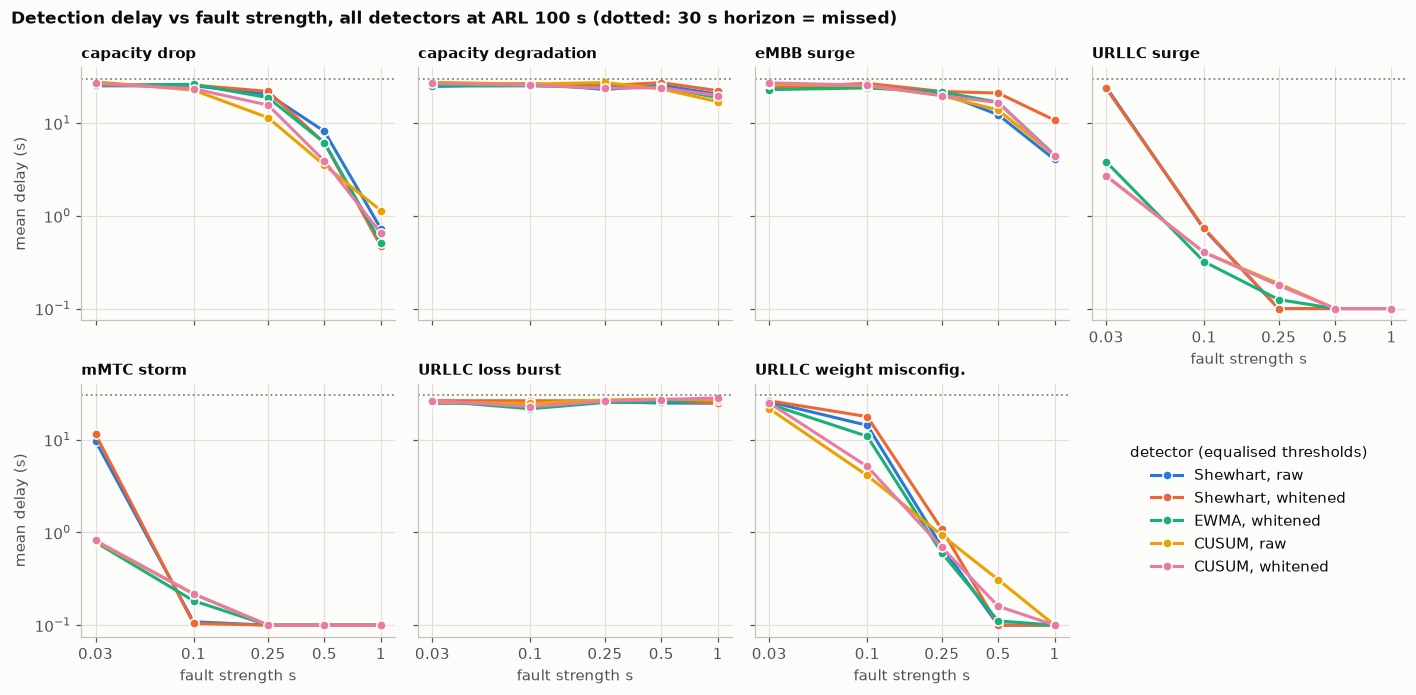

In [6]:
order = list(NICE.values())
fig, axes = plt.subplots(2, 4, figsize=(13, 6.4), sharex=True, sharey=True)
for ax, scen in zip(axes.ravel(), order):
    g = eq[eq.scenario == scen]
    for col, det in zip(PALETTE, DETECTORS):
        d = g[g.detector == det].sort_values("strength")
        ax.plot(d.strength, d.delay_mean_s, "o-", color=col, label=det, mec=SURFACE, mew=1)
    ax.set_title(scen, fontsize=10)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axhline(HORIZON_W * 0.1, color=MUTED, ls=":", lw=1.2)
axes.ravel()[-1].axis("off")
handles, labels = axes[0, 0].get_legend_handles_labels()
axes.ravel()[-1].legend(handles, labels, loc="center", title="detector (equalised thresholds)")
for ax in axes[1]:
    ax.set_xlabel("fault strength s")
for ax in axes[:, 0]:
    ax.set_ylabel("mean delay (s)")
for ax in axes.ravel()[:7]:
    ax.set_xticks(STRENGTHS, [f"{s:g}" for s in STRENGTHS]); ax.minorticks_off()
axes[0, 3].set_xlabel("fault strength s"); axes[0, 3].xaxis.set_tick_params(labelbottom=True)
fig.suptitle("Detection delay vs fault strength, all detectors at ARL 100 s (dotted: 30 s horizon = missed)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig2_delay_sweep")
plt.show()

In [7]:
print("Fraction detected within 30 s (equalised thresholds)")
eq.pivot_table(index=["scenario", "strength"], columns="detector", values="detected").round(2)

Fraction detected within 30 s (equalised thresholds)


detector                          CUSUM, raw  CUSUM, whitened  EWMA, whitened  \
scenario                strength                                                
URLLC loss burst        0.03            0.25             0.16            0.29   
                        0.10            0.34             0.36            0.39   
                        0.25            0.27             0.32            0.39   
                        0.50            0.26             0.19            0.24   
                        1.00            0.22             0.13            0.13   
URLLC surge             0.03            1.00             1.00            1.00   
                        0.10            1.00             1.00            1.00   
                        0.25            1.00             1.00            1.00   
                        0.50            1.00             1.00            1.00   
                        1.00            1.00             1.00            1.00   
URLLC weight misconfig. 0.03            0.44             0.31            0.34   
                        0.10            1.00             1.00            1.00   
                        0.25            1.00             1.00            1.00   
                        0.50            1.00             1.00            1.00   
                        1.00            1.00             1.00            1.00   
capacity degradation    0.03            0.21             0.28            0.38   
                        0.10            0.25             0.31            0.25   
                        0.25            0.24             0.35            0.27   
                        0.50            0.62             0.57            0.38   
                        1.00            1.00             1.00            0.89   
capacity drop           0.03            0.12             0.16            0.32   
                        0.10            0.45             0.39            0.21   
                        0.25            1.00             0.83            0.77   
                        0.50            1.00             1.00            1.00   
                        1.00            1.00             1.00            1.00   
eMBB surge              0.03            0.16             0.13            0.40   
                        0.10            0.25             0.29            0.31   
                        0.25            0.63             0.60            0.52   
                        0.50            0.81             0.77            0.74   
                        1.00            1.00             1.00            1.00   
mMTC storm              0.03            1.00             1.00            1.00   
                        0.10            1.00             1.00            1.00   
                        0.25            1.00             1.00            1.00   
                        0.50            1.00             1.00            1.00   
                        1.00            1.00             1.00            1.00   

detector                          Shewhart, raw  Shewhart, whitened  
scenario                strength                                     
URLLC loss burst        0.03               0.31                0.26  
                        0.10               0.30                0.23  
                        0.25               0.30                0.23  
                        0.50               0.32                0.22  
                        1.00               0.27                0.28  
URLLC surge             0.03               0.31                0.40  
                        0.10               1.00                1.00  
                        0.25               1.00                1.00  
                        0.50               1.00                1.00  
                        1.00               1.00                1.00  
URLLC weight misconfig. 0.03               0.27                0.25  
                        0.10               0.84                0.63  
                      

**What the sweep shows** (equalised thresholds, ARL 100 s)

A caution first. With ARL 100 s and a 30 s horizon, a detector alarms *by chance* in about 26% of runs ($1 - e^{-0.3}$). "Detected" fractions of 0.15–0.4 therefore mean **not detected**.

- **Faults concentrated in one slice are caught almost at once, even when small.** A URLLC surge of ×1.17 ($s = 0.1$) is caught in 0.3–0.7 s; an mMTC storm of only ×1.03 ($s = 0.03$) in 0.8 s by CUSUM and EWMA. These faults show in throughput, a stream with no memory and little noise, where a few percent more traffic stands out.
- **Detectors with memory win on small shifts, as theory says.** At $s = 0.03$, CUSUM catches the URLLC surge in 2.7 s, while Shewhart mostly misses it (23–24 s). For the mMTC storm the figures are 0.8 s and about 10 s.
- **Shared faults are the hard ones.**
  - **Capacity drop.** It needs $s = 0.25$ (an 8.5% capacity loss) before CUSUM catches it reliably (raw: 11.4 s, all runs). At $s = 0.1$ (a 3.5% loss) no detector beats chance.
  - **eMBB surge.** It is caught in about 4.5 s only at full strength (+30% traffic).
  - **Capacity degradation.** It is caught after 17–20 s even at full strength, because the 60 s ramp is only half-way through when the 30 s horizon ends.
- **The URLLC loss burst is not detected** (chance level), as expected: URLLC loss is not monitored, and it needs a count-based detector.
- **Once thresholds come from simulation, whitening does not help.** Raw-score CUSUM is as good as or better than whitened CUSUM; for example, the capacity drop at $s = 0.25$ takes 11.4 s raw against 15.6 s whitened. Whitening shrinks a sustained shift by about $\sqrt{(1-\phi)/(1+\phi)}$ (notebook 04), while simulation-based calibration already accounts for the memory. Whitening is still essential when thresholds come from theory, and it makes them less dependent on the simulator matching reality.

## 4. Does equalising the thresholds help?

The same sweep, scored with one common threshold for all streams (the "max over streams" with no per-stream calibration). Values are mean delay in seconds, averaged over the five strengths. Lower is better.

In [8]:
cmp = sweep.pivot_table(index=["detector", "thresholds"], values=["delay_mean_s", "detected"], aggfunc="mean")
by_fault = sweep[sweep.detector == "CUSUM, whitened"].pivot_table(index="scenario", columns="thresholds",
                                                                  values="delay_mean_s", aggfunc="mean")
display(cmp.round(2))
by_fault.round(2)

delay_mean_s  detected
detector           thresholds                        
CUSUM, raw         common             12.93      0.71
                   equalised          12.57      0.70
CUSUM, whitened    common             13.06      0.69
                   equalised          12.85      0.69
EWMA, whitened     common             15.07      0.62
                   equalised          12.90      0.69
Shewhart, raw      common             17.53      0.53
                   equalised          13.93      0.67
Shewhart, whitened common             17.21      0.56
                   equalised          14.94      0.63

thresholds,common,equalised
scenario,,
URLLC loss burst,27.53,26.06
URLLC surge,1.43,0.69
URLLC weight misconfig.,7.12,6.20
capacity degradation,24.76,23.98
capacity drop,13.86,14.08
eMBB surge,16.19,18.70
mMTC storm,0.53,0.27


**What it shows**

- **Equalising thresholds helps most for the memoryless detectors.** Shewhart on raw scores drops from 17.5 to 13.9 s mean delay (detection 53% → 67%), and EWMA from 15.1 to 12.9 s.
- **For CUSUM it hardly matters on average** (raw 12.9 → 12.6 s, whitened 13.1 → 12.9 s), but it moves delay between faults. For whitened CUSUM, faults visible in light-tailed streams get faster (URLLC surge 1.4 → 0.7 s), while the eMBB surge, seen mainly in heavy-tailed eMBB streams, gets slower (16.2 → 18.7 s). Equalising is a choice of which faults to favour, not a free gain.

## 5. Does the alarm point to the right slice?

Each alarm comes from one stream, so it also names a slice. For faults that target one slice, how often is it the right one? (Equalised thresholds; all strengths with detections pooled.)

In [9]:
loc = eq.dropna(subset=["right_slice"]).groupby(["scenario", "detector"]).apply(
    lambda g: np.average(g.right_slice, weights=g.detected.fillna(0) + 1e-12), include_groups=False).unstack()
loc.round(2)

detector,"CUSUM, raw","CUSUM, whitened","EWMA, whitened","Shewhart, raw","Shewhart, whitened"
scenario,,,,,
URLLC loss burst,0.27,0.14,0.14,0.28,0.36
URLLC surge,0.99,1.00,1.00,0.99,0.98
URLLC weight misconfig.,0.93,0.95,0.94,0.94,0.93
eMBB surge,0.80,0.77,0.76,0.82,0.66
mMTC storm,1.00,1.00,1.00,0.99,0.98


**What it shows**

- **The first alarm usually names the right slice.** It does so in 93–100% of detections for the URLLC surge, the weight misconfiguration and the mMTC storm, and in 66–82% for the eMBB surge.
- **The loss-burst numbers are noise.** They are chance alarms, not detections.

Per-stream monitoring thus gives a first diagnosis for free: *which* slice is in trouble.

In [10]:
# Export tables and key numbers for report/main.tex
tab = calib_table.assign(
    h_iid=calib_table.h_iid.map(lambda v: "--" if pd.isna(v) else f"{v:.1f}"),
    arl_if_iid_threshold=calib_table.arl_if_iid_threshold.map(lambda v: "--" if pd.isna(v) else f"{v:.0f}"),
    h_common=calib_table.h_common.map("{:.1f}".format),
    stream_h=[f"{a:.1f}--{b:.1f}" for a, b in zip(calib_table.stream_h_min, calib_table.stream_h_max)],
)[["detector", "h_iid", "arl_if_iid_threshold", "h_common", "stream_h", "heaviest_stream"]]
tab.columns = ["detector", "$h$ (i.i.d.)", "ARL at i.i.d. $h$", "$h$ (common)", "per-stream $h$", "heaviest stream"]
save_tex_table(tab, "calibration", "lrrrrl")

piv = eq.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s").reindex(columns=list(DETECTORS))
det_piv = eq.pivot_table(index=["scenario", "strength"], columns="detector", values="detected").reindex(columns=list(DETECTORS))
cells = piv.copy().astype(object)
for c in piv.columns:
    cells[c] = [f"{d:.1f}" if p >= 0.995 else f"{d:.1f} ({100 * p:.0f}\\%)" for d, p in zip(piv[c], det_piv[c])]
cells = cells.reset_index()
cells["scenario"] = [sc if i == 0 or sc != cells.scenario[i - 1] else "" for i, sc in enumerate(cells.scenario)]
cells["strength"] = cells.strength.map("{:g}".format)
cells.columns = ["fault", "$s$", *[c.replace(", ", " ") for c in DETECTORS]]
save_tex_table(cells, "sweep", "llrrrrr")

def g(scen, s, det, col="delay_mean_s"):
    return eq[(eq.scenario == scen) & (eq.strength == s) & (eq.detector == det)][col].iloc[0]
CT = calib_table.set_index("detector")
save_tex_numbers({
    "TargetArlS": f"{TARGET_ARL * 0.1:.0f}",
    "HiidShew": f"{h_iid['Shewhart']:.1f}", "HiidCusum": f"{h_iid['CUSUM']:.1f}",
    "HcommonShewRaw": f"{CT.loc['Shewhart, raw', 'h_common']:.1f}",
    "HcommonCusumWhite": f"{CT.loc['CUSUM, whitened', 'h_common']:.1f}",
    "HcommonCusumRaw": f"{CT.loc['CUSUM, raw', 'h_common']:.1f}",
    "ArlIidCusumRaw": f"{CT.loc['CUSUM, raw', 'arl_if_iid_threshold']:.0f}",
    "ArlIidCusumWhite": f"{CT.loc['CUSUM, whitened', 'arl_if_iid_threshold']:.0f}",
    "DelayCapDropQuarterCW": f"{g('capacity drop', 0.25, 'CUSUM, whitened'):.1f}",
    "DelayCapDropQuarterSR": f"{g('capacity drop', 0.25, 'Shewhart, raw'):.1f}",
    "DelayUrllcTenthCW": f"{g('URLLC surge', 0.1, 'CUSUM, whitened'):.1f}",
    "DelayEmbbTenthCW": f"{g('eMBB surge', 0.1, 'CUSUM, whitened'):.1f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("05_*")))

exported: ['05_calibration.tex', '05_numbers.tex', '05_sweep.tex']


## 6. Summary

- **Calibrate by simulation, never by i.i.d. formulas.** On real-looking KPIs, i.i.d. thresholds give 10–40 times too many false alarms. The heaviest-tailed stream (eMBB loss) dominates a "max over streams" detector unless each stream gets its own threshold.
- **Faults concentrated in one slice are easy.** CUSUM and EWMA catch traffic changes of a few percent within about a second, mostly through throughput, and the alarm names the right slice more than 90% of the time.
- **Shared faults are hard.** A capacity drop below about 8% is not detected within 30 s at ARL 100 s, and notebook 04 showed that coupling between slices hardly helps for them. Better shared-fault detection needs more information, not a cleverer combination of the same KPIs. An observable resource-utilisation KPI (the PRB utilisation a real RAN reports) is the obvious candidate.
- **Whitening is unnecessary once thresholds are simulated.** Raw-score CUSUM matches or beats whitened CUSUM on step faults.
- **Loss on URLLC needs a count model.** With Gaussian detectors, the loss burst goes unnoticed.